<a href="https://colab.research.google.com/github/hoodgavin216-a11y/ThrustStand/blob/main/analysis/MPU_Finite_Analysis_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Load raw MPU6050 motor vibration data (Speed Level 2) directly from GitHub
url = "https://raw.githubusercontent.com/JonasSouza871/Motor_Vibration_Classification_TinyML/main/data/nivel2.csv"
df = pd.read_csv(url)

# Preview the first 5 rows and check column names
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1203 entries, 0 to 1202
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Amostra      1203 non-null   int64  
 1   Acel_X       1203 non-null   float64
 2   Acel_Y       1203 non-null   float64
 3   Acel_Z       1203 non-null   float64
 4   Giro_X       1203 non-null   float64
 5   Giro_Y       1203 non-null   float64
 6   Giro_Z       1203 non-null   float64
 7   Temperatura  1203 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 75.3 KB
None


,Amostra,Acel_X,Acel_Y,Acel_Z,Giro_X,Giro_Y,Giro_Z,Temperatura
0,1,-3.334,1.454,9.786,1.992,-2.756,1.924,16.34
1,2,1.008,-0.381,9.966,3.328,5.015,1.466,16.34
2,3,-0.271,-1.027,10.490,1.611,-2.527,2.878,16.15
3,4,1.320,-0.934,10.368,0.366,3.366,4.031,16.25
4,5,-3.892,0.304,10.260,-1.313,-1.687,1.359,16.25


In [2]:
import math as m
total_accel_scalar=np.sqrt(df.Acel_X**2+df.Acel_Y**2+df.Acel_Z**2)
print(total_accel_scalar)
mean_accel=np.mean(total_accel_scalar)
print(f'mean acceleration over 1203:  {(m.trunc(mean_accel*10000))/10000} m/s^2')
df['Total_Accel']=total_accel_scalar
df.head()
Acel_Spike=np.subtract(df.Total_Accel,mean_accel)
df['Acel_Spike']=Acel_Spike
df.head()


0       10.440089
1       10.024090
2       10.543636
3       10.493340
4       10.977599
          ...    
1198     9.598231
1199     9.851296
1200     9.769915
1201    10.451317
1202    10.246939
Length: 1203, dtype: float64
mean acceleration over 1203:  10.2819 m/s^2


,Amostra,Acel_X,Acel_Y,Acel_Z,Giro_X,Giro_Y,Giro_Z,Temperatura,Total_Accel,Acel_Spike
0,1,-3.334,1.454,9.786,1.992,-2.756,1.924,16.34,10.440089,0.158181
1,2,1.008,-0.381,9.966,3.328,5.015,1.466,16.34,10.024090,-0.257819
2,3,-0.271,-1.027,10.490,1.611,-2.527,2.878,16.15,10.543636,0.261728
3,4,1.320,-0.934,10.368,0.366,3.366,4.031,16.25,10.493340,0.211431
4,5,-3.892,0.304,10.260,-1.313,-1.687,1.359,16.25,10.977599,0.695690


In [3]:
Stdev_acel=np.std(Acel_Spike)
print(f'Standard Deviation of acceleration over 1203:  {(m.trunc(Stdev_acel*10000))/10000} m/s^2')



Standard Deviation of acceleration over 1203:  0.3967 m/s^2


In [4]:
#rounding func
def round_4_func(num):
  return round(num, 4)


Total_Acel_Max=(total_accel_scalar).max()
print(f'Max Accleration (sum xyz): {round_4_func(Total_Acel_Max)} m/s^2')
Total_Acel_Min=(total_accel_scalar).min()
print(f'Minimum Accleration (sum xyz): {round_4_func(Total_Acel_Min)} m/s^2')
Peak_to_Peak_Acel=(round_4_func((Total_Acel_Max)-(Total_Acel_Min)))
print(f'Peak-to-Peak Accleration (sum xyz): {Peak_to_Peak_Acel} m/s^2')
Crest_Factor_Acel=(round_4_func((Peak_to_Peak_Acel)/(Stdev_acel)))
print(f'Crest Factor Accleration (sum xyz): {Crest_Factor_Acel} m/s^2 ')

Max Accleration (sum xyz): 11.3246 m/s^2
Minimum Accleration (sum xyz): 9.3026 m/s^2
Peak-to-Peak Accleration (sum xyz): 2.022 m/s^2
Crest Factor Accleration (sum xyz): 5.0967 m/s^2 


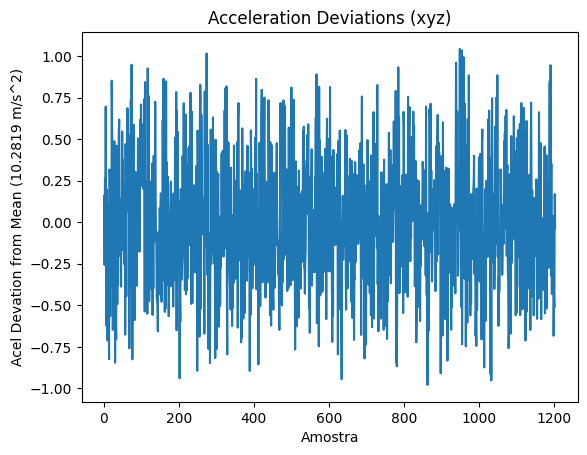

In [5]:
plt.plot(df.Amostra,df.Acel_Spike)
plt.title('Acceleration Deviations (xyz)')
plt.xlabel('Amostra')
plt.ylabel('Acel Devation from Mean (10.2819 m/s^2)')
plt.show()

   Amostra  Acel_X  Acel_Y  Acel_Z  Giro_X  Giro_Y  Giro_Z  Temperatura  \
0        1  -3.334   1.454   9.786   1.992  -2.756   1.924        16.34   
1        2   1.008  -0.381   9.966   3.328   5.015   1.466        16.34   
2        3  -0.271  -1.027  10.490   1.611  -2.527   2.878        16.15   
3        4   1.320  -0.934  10.368   0.366   3.366   4.031        16.25   
4        5  -3.892   0.304  10.260  -1.313  -1.687   1.359        16.25   

   Total_Accel  Acel_Spike  Accel_Rolling_Average  
0    10.440089    0.158181               0.158181  
1    10.024090   -0.257819              -0.049819  
2    10.543636    0.261728               0.054030  
3    10.493340    0.211431               0.093380  
4    10.977599    0.695690               0.213842  


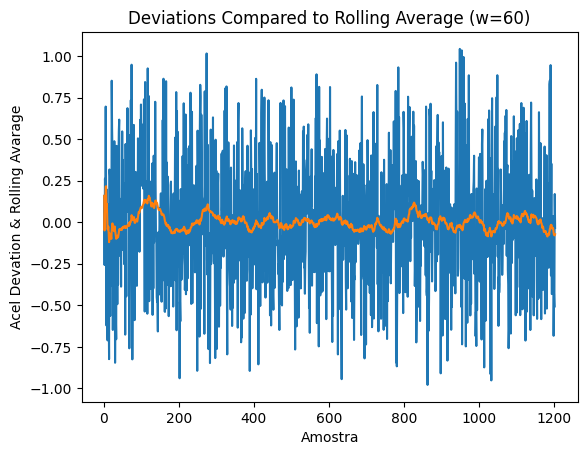

In [6]:
window_size=60 #will analyize later to see what window works best

df['Accel_Rolling_Average']=df['Acel_Spike'].rolling(window=window_size, min_periods=1).mean()
Accel_Rolling_Average=df['Accel_Rolling_Average']
print(df.head())

plt.plot(df.Amostra,df.Acel_Spike)
plt.plot(df.Amostra,Accel_Rolling_Average)
plt.title(f'Deviations Compared to Rolling Average (w={window_size})')
plt.xlabel('Amostra')
plt.ylabel('Acel Devation & Rolling Avarage')
plt.show()

In [7]:
high_frequency_residual=np.subtract(df.Acel_Spike,df.Accel_Rolling_Average)
df['High_Frequency_Residual']=high_frequency_residual
print(df.head())

   Amostra  Acel_X  Acel_Y  Acel_Z  Giro_X  Giro_Y  Giro_Z  Temperatura  \
0        1  -3.334   1.454   9.786   1.992  -2.756   1.924        16.34   
1        2   1.008  -0.381   9.966   3.328   5.015   1.466        16.34   
2        3  -0.271  -1.027  10.490   1.611  -2.527   2.878        16.15   
3        4   1.320  -0.934  10.368   0.366   3.366   4.031        16.25   
4        5  -3.892   0.304  10.260  -1.313  -1.687   1.359        16.25   

   Total_Accel  Acel_Spike  Accel_Rolling_Average  High_Frequency_Residual  
0    10.440089    0.158181               0.158181                 0.000000  
1    10.024090   -0.257819              -0.049819                -0.208000  
2    10.543636    0.261728               0.054030                 0.207698  
3    10.493340    0.211431               0.093380                 0.118051  
4    10.977599    0.695690               0.213842                 0.481848  


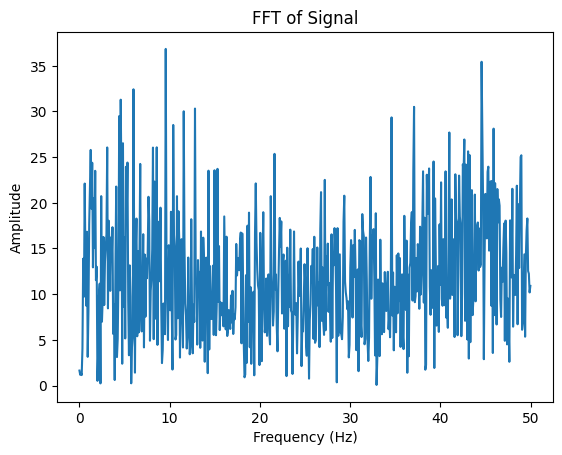

Max Amplitude: 36.85046324370769
Hz at Max Amplitude: 9.559434746467165
RPM: 573.5660847880299


In [23]:
#Fast Fourier Transform

signal=df.High_Frequency_Residual.dropna()
fs=100.0 #placeholder for Hz as data set came without time
d=1/fs
N=len(signal)
fft_amplitude=np.abs(np.fft.rfft(signal)) #fft.rfft to do quick FFT transform
fft_frequency=np.fft.rfftfreq(N,d)
plt.plot(fft_frequency, fft_amplitude)
plt.title('FFT of Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.show()

fft_amplitude_MAX=fft_amplitude.max()
print(f'Max Amplitude: {fft_amplitude_MAX}')
fft_frequency_Max=np.argmax(fft_amplitude)
print(f'Hz at Max Amplitude: {fft_frequency[fft_frequency_Max]}')
print(f'RPM: {(fft_frequency[fft_frequency_Max])*60}')
